# Molecular Hamiltonians: active-space resources and accuracy

**Question:** how does expanding a controlled active space change qubit/measurement resources and correlation energy for NH₃, H₂CO₃, and HCO₃⁻?

Use fixed geometries and canonical RHF orbitals, construct effective fermionic and qubit Hamiltonians, and compare matched-sector diagonalization with CASCI. Resource counts and energy errors are separate observables. Run instructions: [README_SCALING.md](README_SCALING.md).


In [1]:
import os, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml
from pyscf import ao2mo
from scaling_benchmark import (load_models, build_model, cas_reference, build_case,
    sector_matrix, resource_metrics, run_study, provenance, require)

profile = os.environ.get("SCALING_PROFILE", "default")
require(profile in {"default", "smoke"}, "Unknown SCALING_PROFILE")
metadata = provenance()
print(json.dumps(metadata, indent=2))


{
  "python": "3.11.15",
  "packages": {
    "numpy": "1.26.4",
    "scipy": "1.17.1",
    "pennylane": "0.36.0",
    "autoray": "0.6.11",
    "pyscf": "2.11.0",
    "matplotlib": "3.11.2",
    "nbclient": "0.11.0",
    "nbformat": "5.11.1"
  },
  "source_sha256": "fb969a4afee275d8095b0813f91eb4237f40b47426c35606a789a0d53413e084",
  "geometries_sha256": "8a63eddcafad6afca4cdd9b2f2de8b5ebd11d70fd4a771680a433da7f9e7ccb5",
  "geometry_unit": "angstrom",
  "basis": "sto-3g",
  "orbital_basis": "fixed canonical RHF per molecule",
  "energy_convention": "total Born-Oppenheimer energy including nuclear repulsion",
  "integral_backend": "PySCF; CASCI and qubit solvers share integral tensors",
  "integral_cutoff": 1e-12,
  "pauli_cutoff": 1e-12,
  "grouping": "deterministic weight-first, lexicographic first-fit QWC; not optimal/shots",
  "max_exact_qubits": 12,
  "max_sector_determinants": 400,
  "max_sparse_action_entries": 2000000,
  "scf_tolerance": 1e-11,
  "casci_tolerance": 1e-12,
  "requ

## 1. Geometries, units, and full-space counts

All coordinates are Å, with singlet multiplicity and STO-3G. NH₃ retains the original approximate fixed geometry. Acid/anion snapshots use seeded RDKit ETKDGv3 embedding and converged UFF optimization; they are model inputs, not experimental structures or quantum-optimized geometries. The default environment reads fixed JSON and needs no RDKit.

RHF/PBE baselines use the full basis. The anion's minimal basis lacks diffuse functions; no electron-binding or carbon-capture thermochemistry claim follows from these inputs.


In [2]:
models = load_models()
for name, spec in models.items():
    print(name, "charge:", spec["charge"], "electrons:", spec["expected_electrons"],
          "spatial orbitals:", spec["expected_spatial_orbitals"],
          "full-space qubits:", 2*spec["expected_spatial_orbitals"])
    print("Geometry / Å:\n", np.array(spec["coordinates_angstrom"]))

model = build_model("ammonia")
casci, space = cas_reference(model, 4, 4)
print("Frozen occupied / active indices:", space["core_indices"], space["active_indices"])


ammonia charge: 0 electrons: 10 spatial orbitals: 8 full-space qubits: 16
Geometry / Å:
 [[ 0.    0.    0.  ]
 [ 0.    0.94  0.31]
 [ 0.82 -0.47  0.31]
 [-0.82 -0.47  0.31]]
carbonic_acid charge: 0 electrons: 32 spatial orbitals: 22 full-space qubits: 44
Geometry / Å:
 [[ 0.07755917  1.34843869 -0.27774459]
 [ 0.0052647   0.09153157 -0.23028425]
 [ 1.15755534 -0.66835724 -0.06441285]
 [-1.22715702 -0.54173416 -0.34355013]
 [ 2.06451842 -0.22491171  0.0199441 ]
 [-2.07774062 -0.00496715 -0.46492005]]
bicarbonate charge: -1 electrons: 32 spatial orbitals: 21 full-space qubits: 42
Geometry / Å:
 [[-0.42440315  1.22948106 -0.92953523]
 [-0.40001173  0.02366982 -0.56860684]
 [-1.53739019 -0.76080711 -0.70102577]
 [ 0.76159193 -0.52562684 -0.03783634]
 [ 1.60021314  0.03328307  0.0655137 ]]


pyscf/lib/misc.py:148: UserWarning: OpenMP is not available. Setting omp_threads to 1 has no effects.
  warnings.warn('OpenMP is not available. '


Frozen occupied / active indices: [0, 1, 2] [3, 4, 5, 6]


## 2. Effective molecular Hamiltonian and mapping

At each molecule, hold the same RHF orbitals fixed and expand frontier spaces CAS(2,2) → CAS(4,4) → CAS(6,6). With $n_c=(N_e-N_e^{\mathrm{active}})/2$, freeze occupied orbitals below $n_c$ and activate the next $N_o^{\mathrm{active}}$ orbitals. This gives nested variational spaces when the frozen scalar is included consistently; CASCI orbitals are not CASSCF-optimized.

For spatial indices and explicit spin labels,
$$H=E_{\mathrm{core}}I+\sum_{pq\sigma}h^{\mathrm{eff}}_{pq}a^\dagger_{p\sigma}a_{q\sigma}+\frac12\sum_{pqrs\sigma\tau}g_{pqrs}a^\dagger_{p\sigma}a^\dagger_{q\tau}a_{r\tau}a_{s\sigma}.$$

$E_{\mathrm{core}}$ contains nuclear repulsion and frozen-occupied energy; $h^{\mathrm{eff}}$ includes frozen-occupied interactions. For real spatial orbitals, convert chemist ERIs to $g_{pqrs}=(ps|rq)$. PennyLane expands spin indices and applies Jordan–Wigner; wire 0 is the leftmost bit, with α/β interleaving.


In [3]:
one_body, core_energy = casci.get_h1eff()
two_body_chemist = ao2mo.restore(1, casci.get_h2eff(), 4)
fermionic = qml.qchem.fermionic_observable(np.array([core_energy]), one_body,
                                         two_body_chemist.swapaxes(1, 3), cutoff=1e-12)
qubit_hamiltonian = qml.qchem.qubit_observable(fermionic, cutoff=1e-12)
print("Effective one-electron MO integrals / Ha:\n", one_body)
print("Spatial two-electron tensor shape:", two_body_chemist.shape)
print("Nuclear / core total scalar / Ha:", model.baseline["nuclear_repulsion_hartree"], core_energy)
print("Fermionic terms:", len(fermionic))
print("Pauli resources:", resource_metrics(qubit_hamiltonian, 8))


Effective one-electron MO integrals / Ha:
 [[-2.24893017e+00 -6.34188778e-03  4.23203609e-02  1.27902022e-11]
 [-6.34188778e-03 -2.19069419e+00 -8.40492865e-02  1.71141306e-12]
 [ 4.23203609e-02 -8.40492865e-02 -1.26008974e+00 -5.22051647e-12]
 [ 1.27903277e-11  1.71116208e-12 -5.21970158e-12 -1.29834046e+00]]
Spatial two-electron tensor shape: (4, 4, 4, 4)
Nuclear / core total scalar / Ha: 12.16200842993348 -50.08317986069255
Fermionic terms: 565
Pauli resources: {'pauli_terms': 193, 'nonidentity_terms': 192, 'identity_coefficient_hartree': -53.48345933556094, 'nonidentity_l1_hartree': 6.115066864653491, 'max_pauli_weight': 8, 'weight_histogram': {'1': 8, '2': 36, '3': 8, '4': 96, '5': 4, '6': 36, '8': 4}, 'greedy_qwc_settings': 43}


## 3. Physical-sector validation and classical references

Project Pauli action onto $N_\alpha=N_\beta=N_e^{\mathrm{active}}/2$, checking cancellation of couplings outside that sector. Verify Hermiticity, singlet character, CASCI agreement within 10⁻⁸ Ha, and the HF determinant's recovery of full RHF energy. CASCI and qubit solvers share integrals: this tests mapping/solver consistency, not independent integral engines.

The largest default block is 400×400 for 12 qubits; no full $2^n\times2^n$ Hamiltonian is built. Larger classical references use direct CASCI: NH₃'s full CAS(10,8) is FCI within STO-3G; acid/anion CAS(8,8) remain truncated references. The latter errors are differences from a containing active space, not full-basis or experimental errors.


In [4]:
basis, block = sector_matrix(qubit_hamiltonian, 4, 4)
exact = float(np.linalg.eigvalsh(block)[0])
np.testing.assert_allclose(exact, casci.e_tot, atol=1e-8, rtol=0)
hf_bits = qml.qchem.hf_state(4, 8)
hf_index = int("".join(map(str, hf_bits)), 2)
hf_position = int(np.searchsorted(basis, hf_index))
np.testing.assert_allclose(block[hf_position,hf_position].real, model.baseline["rhf_hartree"], atol=1e-8, rtol=0)
print("HF occupations:", hf_bits)
print("Sector size:", len(basis), "| sector exact / CASCI / Ha:", exact, casci.e_tot)


HF occupations: [1 1 1 1 0 0 0 0]
Sector size: 36 | sector exact / CASCI / Ha: -55.4536997760783 -55.45369977607832


## 4. Resource–accuracy study

Count canonical Pauli terms at a fixed 10⁻¹² cutoff, nonidentity coefficient L₁ norm, maximum Pauli weight, and deterministic greedy qubit-wise commuting (QWC) settings. These settings are compatible measurement bases, not an optimal grouping, shot estimate, hardware gate count, or runtime prediction. Counts depend on orbital basis, mapping, cutoff, and grouping heuristic. Record construction timings as observations on one machine.

Within each nested hierarchy, energies must decrease toward the containing reference. RHF/PBE totals are separate full-basis baselines; PBE need not obey the wavefunction variational bound. Grid levels 5 and 7 are checked at all three fixed geometries.


In [5]:
evidence = run_study(profile)
for molecule in evidence["molecules"]:
    print("\n", molecule["baseline"]["name"], "reference:", molecule["reference"]["scope"])
    print("RHF / PBE / containing CASCI totals / Ha:", molecule["baseline"]["rhf_hartree"],
          molecule["baseline"]["rks_pbe_hartree"], molecule["reference"]["casci_hartree"])
    print("PBE grid5-to7 shift / Ha:", molecule["pbe_grid_control"]["difference_hartree"])
    print("active e/o | qubits | Pauli terms | QWC settings | error vs reference / mHa")
    for row in molecule["cases"]:
        print(row["active_electrons"], row["active_orbitals"], row["qubits"], row["pauli_terms"],
              row["greedy_qwc_settings"], 1000*row["error_vs_larger_reference_hartree"])



 ammonia reference: full STO-3G FCI
RHF / PBE / containing CASCI totals / Ha: -55.449251834655584 -55.70067175617345 -55.5102110930238
PBE grid5-to7 shift / Ha: -8.920864047468058e-09
active e/o | qubits | Pauli terms | QWC settings | error vs reference / mHa
2 2 4 27 9 59.82000787664532
4 4 8 193 43 56.51131694548184
6 6 12 923 296 24.04725812504438

 carbonic_acid reference: larger CAS(8,8), not full-basis FCI
RHF / PBE / containing CASCI totals / Ha: -260.0381094537507 -261.04220120728604 -260.0766139065856
PBE grid5-to7 shift / Ha: 1.3790156572213164e-08
active e/o | qubits | Pauli terms | QWC settings | error vs reference / mHa
2 2 4 27 9 10.429030626596614
4 4 8 193 42 10.074278253682678
6 6 12 819 239 6.991073477990994

 bicarbonate reference: larger CAS(8,8), not full-basis FCI
RHF / PBE / containing CASCI totals / Ha: -259.29817538258146 -260.32241860345516 -259.35799773396536
PBE grid5-to7 shift / Ha: 5.146046078152722e-08
active e/o | qubits | Pauli terms | QWC settings | e

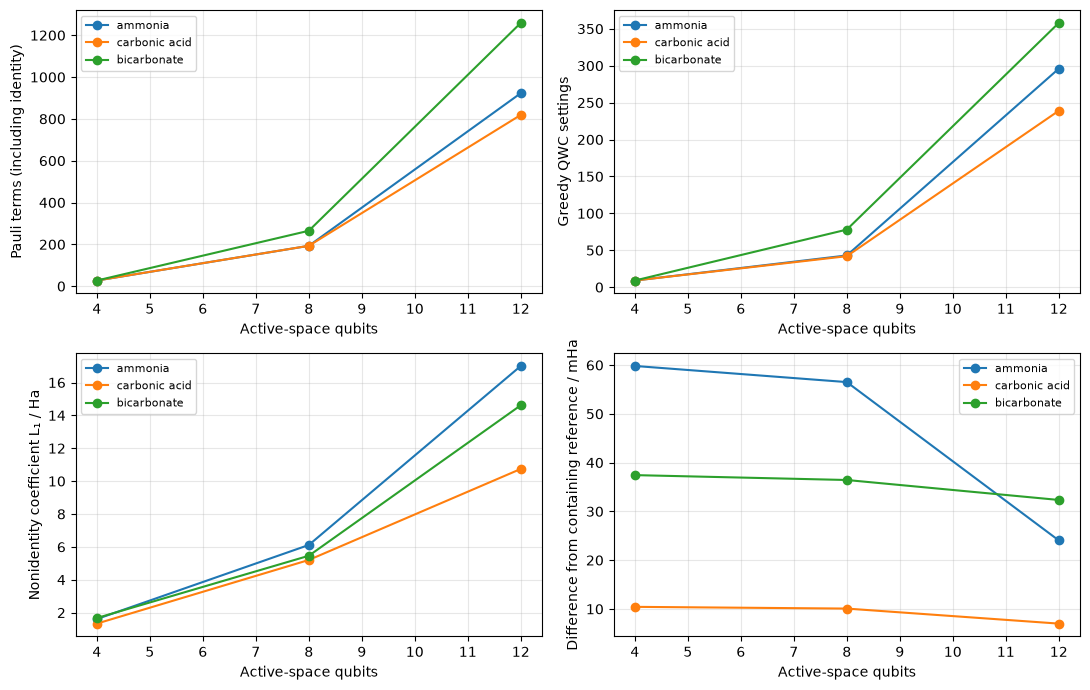

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for molecule in evidence["molecules"]:
    rows = molecule["cases"]
    q = [row["qubits"] for row in rows]
    label = molecule["baseline"]["name"].replace("_", " ")
    for ax, key in zip(axes.flat, ["pauli_terms", "greedy_qwc_settings", "nonidentity_l1_hartree",
                                 "error_vs_larger_reference_hartree"]):
        values = [row[key]*(1000 if key.startswith("error") else 1) for row in rows]
        ax.plot(q, values, "o-", label=label)
for ax, title in zip(axes.flat, ["Pauli terms (including identity)", "Greedy QWC settings",
                                "Nonidentity coefficient L₁ / Ha", "Difference from containing reference / mHa"]):
    ax.set(xlabel="Active-space qubits", ylabel=title)
    ax.grid(alpha=.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 5. Identity coefficients and resource limits

The mapped identity coefficient C₀ also contains contributions from active electronic operators. It differs from both nuclear repulsion and the frozen-core scalar; its trend is not a variational energy or molecular stability criterion.

Full-space counts of 16/44/42 qubits are metadata, not measured full-space Pauli costs. Default execution stops at 12 qubits. An explicit opt-in constructs 16-qubit operators using 8-orbital spaces; these use converged CASCI integrals and an HF-energy check, without qubit-spectrum validation. Still larger/full-space operators are outside this bounded study.


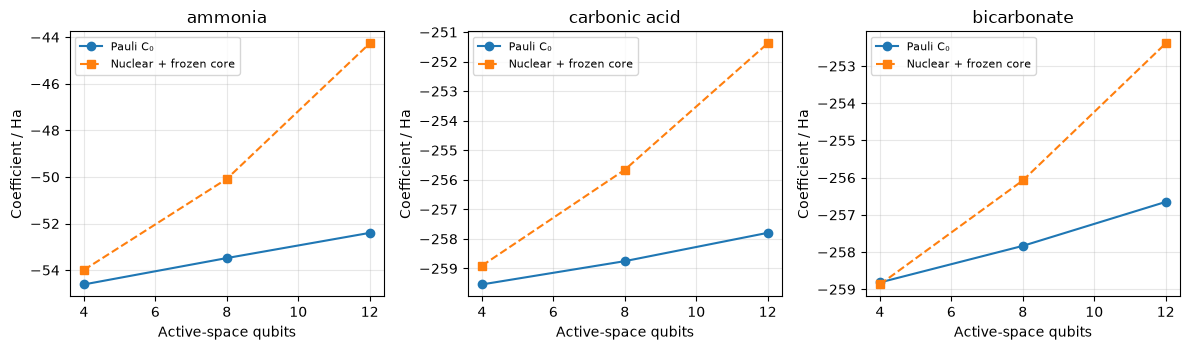

In [7]:
constant_fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, molecule in zip(axes, evidence["molecules"]):
    rows = molecule["cases"]; q = [r["qubits"] for r in rows]
    ax.plot(q, [r["identity_coefficient_hartree"] for r in rows], "o-", label="Pauli C₀")
    ax.plot(q, [r["core_constant_hartree"] for r in rows], "s--", label="Nuclear + frozen core")
    ax.set(title=molecule["baseline"]["name"].replace("_", " "), xlabel="Active-space qubits", ylabel="Coefficient / Ha")
    ax.grid(alpha=.3); ax.legend(fontsize=8)
constant_fig.tight_layout()
plt.show()

large = []
if os.environ.get("SCALING_LARGE_OPERATORS") == "1":
    for name in models:
        large_model = build_model(name)
        electrons = 10 if name == "ammonia" else 8
        case, _ = build_case(large_model, electrons, 8, allow_large=True)
        large.append(dict(name=name, case=case))
evidence["large_operator_cases"] = large


## 6. Evidence and interpretation

Save all effective integrals, energies, resource definitions, cutoffs, geometry provenance, software versions, and source digests. Replay saved tensors to validate metrics without relying on orbital sign choices. At these inputs, expanding the active spaces improves energy while increasing operator resources; it does not establish converged chemistry. Fixed force-field/approximate geometries, minimal basis, omitted correlation outside the reference, and the anion's missing diffuse functions limit interpretation. This construction study makes no VQE, hardware, carbon-capture efficacy, or quantum-advantage claim.

**Finding for these inputs:** the largest default operators contain 819–1259 Pauli terms and 239–358 greedy QWC settings. Their energy differences from the containing references remain 6.99–32.34 mHa. Increasing active-space size improves this controlled model hierarchy, while these samples do not establish converged chemistry or asymptotic resource scaling.


In [8]:
output = Path(os.environ.get("SCALING_OUTPUT_DIR", "artifacts/scaling"))
output.mkdir(parents=True, exist_ok=True)
(output/"results.json").write_text(json.dumps(evidence, indent=2)+"\n")
fig.savefig(output/"resources_and_accuracy.png", dpi=160)
constant_fig.savefig(output/"constant_terms.png", dpi=160)
print("PASS: reference, sector, nesting, grid, and resource-budget checks")
print("Evidence saved to", output)


PASS: reference, sector, nesting, grid, and resource-budget checks
Evidence saved to artifacts/scaling


## References

[PySCF active-space methods](https://pyscf.org/user/mcscf.html), [FCI](https://pyscf.org/user/ci.html),
[PennyLane quantum chemistry](https://docs.pennylane.ai/en/stable/introduction/chemistry.html), and
[RDKit geometry tools](https://www.rdkit.org/docs/GettingStartedInPython.html).

Commands, failures, and remaining checks: [VALIDATION.md#scaling](VALIDATION.md#scaling).
